# 08 · Review DINOv3 mistakes with Meta Muse Spark

This Colab notebook finds every DINOv3 error in notebook 03's saved internal test predictions, adds five reproducibly sampled correct images, then asks Muse Spark to classify the same photographs from the same 18 classes. It reads saved predictions and does not load or rerun DINOv3.

Images are checked against the dataset SHA-256 before display or upload. Meta responses are cached to Drive after each call, so rerunning the notebook skips completed requests. Total API calls equal the number of mistakes plus five. Calls may incur charges.

This is a small error review, not a benchmark or toxicity assessment. Possible near-duplicate images across splits may make results look better than performance on new photographs.

## 1. Install the Meta API client

Run in Colab with access to your experiment files in Google Drive. Add MODEL_API_KEY to Colab Secrets and grant this notebook access.

In [1]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'openai>=1.0,<3'])

0

## 2. Connect to the saved run and dataset

In [2]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import base64, hashlib, json, os, sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
from openai import OpenAI

SEED = 42
DATASET_VERSION = 'v20261026_2355546'
MODEL_ID = 'muse-spark-1.3'
CORRECT_IMAGES = 5
if 'google.colab' not in sys.modules:
    raise RuntimeError('Run this notebook in Google Colab.')
from google.colab import drive, userdata
drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive')
EXPERIMENT_ID = f'plant_export_{DATASET_VERSION}_holdout10_seed{SEED}'
RUNS_DIR = DRIVE_ROOT / 'AI/meta-global-hackaton/runs' / EXPERIMENT_ID
ARCHIVE_PATH = DRIVE_ROOT / 'AI/meta-global-hackaton/data' / f'{EXPERIMENT_ID}.zip'
MODEL_DIR = RUNS_DIR / 'dinov3'
for path in [RUNS_DIR / 'test.csv', MODEL_DIR / 'test_predictions.csv', MODEL_DIR / 'class_mapping.json', MODEL_DIR / 'dataset_metadata.json', ARCHIVE_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path}; check Drive paths and run notebook 03.')
print('DINOv3 run:', MODEL_DIR)
print('Dataset archive:', ARCHIVE_PATH.name)

Mounted at /content/drive
DINOv3 run: /content/drive/MyDrive/AI/meta-global-hackaton/runs/plant_export_v20261026_2355546_holdout10_seed42/dinov3
Dataset archive: plant_export_v20261026_2355546_holdout10_seed42.zip


## 3. Find all DINOv3 mistakes and sample five correct images

The saved predictions must match notebook 03's test manifest. Every mistake is included; the correct comparison group is sampled with seed 42.

In [3]:
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))
metadata = read_json(MODEL_DIR / 'dataset_metadata.json')
mapping = read_json(MODEL_DIR / 'class_mapping.json')
if metadata.get('version_tag') != DATASET_VERSION:
    raise ValueError(f"Unexpected dataset version: {metadata.get('version_tag')}")
CLASS_NAMES = mapping['index_to_class']
if len(CLASS_NAMES) != 18:
    raise ValueError(f'Expected 18 classes, got {len(CLASS_NAMES)}')
test_df = pd.read_csv(RUNS_DIR / 'test.csv')
predictions = pd.read_csv(MODEL_DIR / 'test_predictions.csv')
if test_df.image_id.duplicated().any() or predictions.image_id.duplicated().any():
    raise ValueError('Duplicate image IDs in the manifest or predictions.')
if set(test_df.image_id) != set(predictions.image_id):
    raise ValueError('DINOv3 predictions do not exactly cover test.csv.')
required = ['image_id','true_index','true_class','predicted_index','predicted_class','correct']
if not set(required).issubset(predictions.columns):
    raise ValueError('DINOv3 prediction CSV is missing required columns.')
review = test_df.merge(predictions[required], on='image_id', validate='one_to_one')
if not (review.target == review.true_index).all() or not (review.class_name == review.true_class).all():
    raise ValueError('Saved labels disagree with the test manifest.')
if not (review.correct.astype(bool) == (review.true_index == review.predicted_index)).all():
    raise ValueError('Saved correct flags disagree with the class indices.')
errors = review[review.true_index != review.predicted_index].copy()
correct = review[review.true_index == review.predicted_index].copy()
if len(correct) < CORRECT_IMAGES:
    raise ValueError('Fewer than five correct predictions are available.')
controls = correct.sample(n=CORRECT_IMAGES, random_state=SEED)
review = pd.concat([errors.assign(review_group='DINOv3 mistake'), controls.assign(review_group='DINOv3 correct sample')], ignore_index=True)
review = review.sort_values(['review_group','image_id']).reset_index(drop=True)
if review.empty:
    raise ValueError('No images were selected for review.')
print(f'Test images: {len(test_df)} | DINOv3 mistakes: {len(errors)} | Correct sample: {len(controls)}')
display(review[['review_group','image_id','class_name','true_class','predicted_class','source_split']])

Test images: 111 | DINOv3 mistakes: 3 | Correct sample: 5


,review_group,image_id,class_name,true_class,predicted_class,source_split
0,DINOv3 correct sample,v20260925_155046/snapshot/test/0004_chlorophyt...,chlorophytum comosum,chlorophytum comosum,chlorophytum comosum,test
1,DINOv3 correct sample,v20260925_155046/snapshot/test/0012_hemerocall...,hemerocallis,hemerocallis,hemerocallis,test
2,DINOv3 correct sample,v20260925_155046/snapshot/train/0014_narcissus...,narcissus,narcissus,narcissus,train
3,DINOv3 correct sample,v20260925_155046/snapshot/train/0016_phalaenop...,phalaenopsis,phalaenopsis,phalaenopsis,train
4,DINOv3 correct sample,v20260925_155046/snapshot/train/0018_saintpaul...,saintpaulia,saintpaulia,saintpaulia,train
5,DINOv3 mistake,v20260925_155046/snapshot/test/0001_aglaonema/...,aglaonema,aglaonema,dieffenbachia,test
6,DINOv3 mistake,v20260925_155046/snapshot/train/0004_chlorophy...,chlorophytum comosum,chlorophytum comosum,aglaonema,train
7,DINOv3 mistake,v20260925_155046/snapshot/val/0005_chrysanthem...,chrysanthemum,chrysanthemum,aloe vera,val


## 4. Verify and inspect the selected photographs

Images are read directly from the packaged ZIP. Every selected file is checked against its manifest SHA-256 before display or upload.

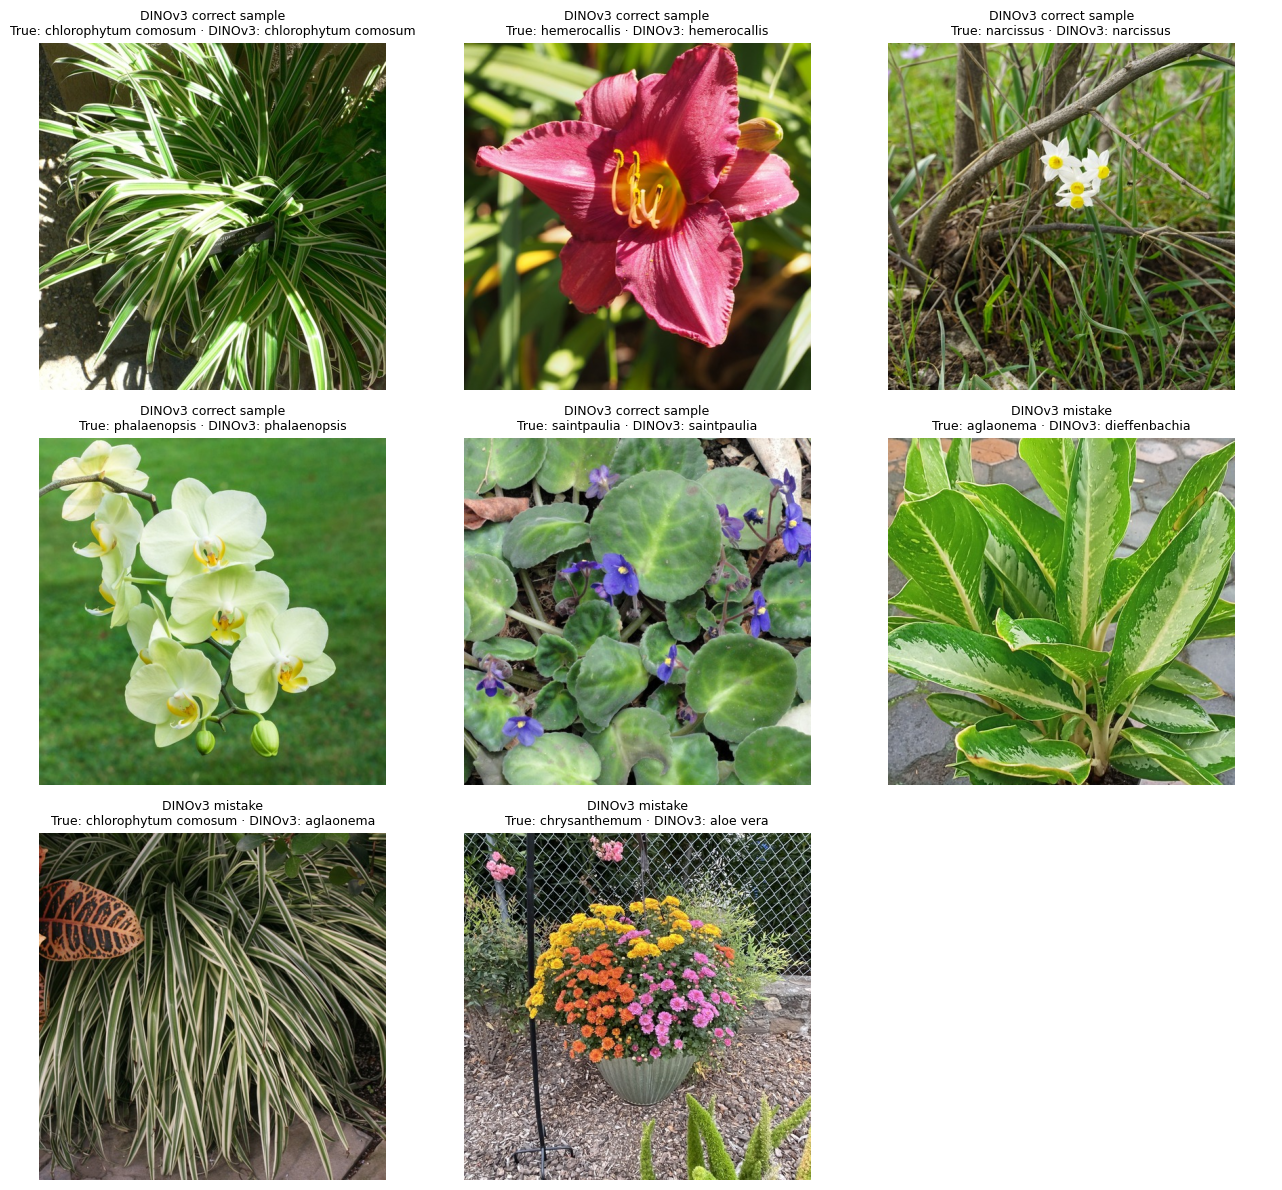

Verified image hashes: 8


In [4]:
selected_images = {}
with ZipFile(ARCHIVE_PATH) as archive:
    for row in review.itertuples(index=False):
        image_bytes = archive.read(row.zip_member)
        if hashlib.sha256(image_bytes).hexdigest() != row.sha256:
            raise ValueError(f'Image hash mismatch: {row.image_id}')
        selected_images[row.image_id] = image_bytes
columns = 3
rows = (len(review) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(13, 4 * rows), squeeze=False)
for ax, row in zip(axes.flat, review.itertuples(index=False)):
    with Image.open(BytesIO(selected_images[row.image_id])) as image:
        ax.imshow(image.convert('RGB'))
    ax.set_title(f'{row.review_group}\nTrue: {row.true_class} · DINOv3: {row.predicted_class}', fontsize=9)
    ax.axis('off')
for ax in axes.flat[len(review):]: ax.axis('off')
fig.tight_layout(); plt.show()
print('Verified image hashes:', len(selected_images))

## 5. Ask Muse Spark to classify the same images

The prompt uses the same 18 labels as DINOv3 and accepts UNKNOWN for an ambiguous image. Responses are cached incrementally in Drive. If a call fails, rerun this cell to continue with uncached images.

In [6]:
CLASS_LIST = '\n'.join(f'- {name}' for name in CLASS_NAMES)
DEVELOPER_PROMPT = ('Identify the main plant shown. Choose exactly one name from the list, or answer UNKNOWN. Return only the class name or UNKNOWN.\n' + CLASS_LIST)
PROMPT_HASH = hashlib.sha256(DEVELOPER_PROMPT.encode()).hexdigest()[:12]
FINGERPRINT = metadata['dataset_fingerprint']
CACHE_PATH = RUNS_DIR / f'muse_spark_dinov3_error_review_{MODEL_ID}_{PROMPT_HASH}_{FINGERPRINT}.csv'
RESULT_PATH = RUNS_DIR / f'dinov3_error_review_{MODEL_ID}_{PROMPT_HASH}_{FINGERPRINT}.csv'
COLUMNS = ['image_id','sha256','model_id','prompt_hash','raw_answer','meta_index','status','input_tokens','cached_input_tokens','output_tokens','estimated_cost_usd']
cache = pd.read_csv(CACHE_PATH) if CACHE_PATH.exists() else pd.DataFrame(columns=COLUMNS)
if not set(COLUMNS).issubset(cache.columns):
    if len(cache): raise ValueError(f'Unexpected cache schema: {CACHE_PATH}')
    cache = pd.DataFrame(columns=COLUMNS)
if cache.image_id.duplicated().any(): raise ValueError('Duplicate IDs in Meta cache.')
if len(cache) and (not cache.model_id.eq(MODEL_ID).all() or not cache.prompt_hash.eq(PROMPT_HASH).all()):
    raise ValueError('Meta cache belongs to a different model or prompt.')
name_to_index = {name.casefold(): i for i, name in enumerate(CLASS_NAMES)}
def parse_answer(answer):
    normalized = answer.strip().strip('"\'').strip().rstrip('.').casefold()
    if normalized == 'unknown': return -1, 'abstained'
    if normalized in name_to_index: return name_to_index[normalized], 'answered'
    return -1, 'invalid'
pending = review[~review.image_id.isin(cache.image_id)]
print(f'New Meta calls: {len(pending)} | Cached: {len(review) - len(pending)}')
if len(pending):
    try: api_key = userdata.get('MODEL_API_KEY')
    except Exception: api_key = os.environ.get('MODEL_API_KEY')
    if not api_key: raise RuntimeError('Set MODEL_API_KEY in Colab Secrets.')
    client = OpenAI(base_url='https://api.meta.ai/v1', api_key=api_key, timeout=90, max_retries=2)
    del api_key
    rates = {'input': 1.25, 'cached_input': 0.15, 'output': 4.25}  # USD per million tokens, Muse Spark 1.3
    for row in pending.itertuples(index=False):
        suffix = Path(row.zip_member).suffix.lower()
        mime = {'.jpg':'image/jpeg','.jpeg':'image/jpeg','.png':'image/png','.webp':'image/webp'}.get(suffix)
        if not mime: raise ValueError(f'Unsupported image type: {suffix}')
        data_url = f'data:{mime};base64,' + base64.b64encode(selected_images[row.image_id]).decode('ascii')
        response = client.chat.completions.create(
            model=MODEL_ID,
            messages=[{'role':'developer','content':DEVELOPER_PROMPT},
                      {'role':'user','content':[{'type':'text','text':'Identify this plant photograph.'},
                       {'type':'image_url','image_url':{'url':data_url}}]}],
            max_completion_tokens=128, reasoning_effort='minimal', seed=SEED)
        answer = response.choices[0].message.content or ''
        meta_index, status = parse_answer(answer)
        usage = response.usage
        input_tokens = int(usage.prompt_tokens) if usage else np.nan
        output_tokens = int(usage.completion_tokens) if usage else np.nan
        details = getattr(usage,'prompt_tokens_details',None) if usage else None
        cached_tokens = getattr(details,'cached_tokens',None) if details else None
        cost = np.nan
        if not pd.isna(input_tokens) and not pd.isna(output_tokens):
            cached_count = int(cached_tokens or 0)
            cost = ((input_tokens-cached_count)*rates['input'] + cached_count*rates['cached_input'] + output_tokens*rates['output'])/1_000_000
        record = {'image_id':row.image_id,'sha256':row.sha256,'model_id':MODEL_ID,'prompt_hash':PROMPT_HASH,
                  'raw_answer':answer,'meta_index':meta_index,'status':status,'input_tokens':input_tokens,
                  'cached_input_tokens':cached_tokens,'output_tokens':output_tokens,'estimated_cost_usd':cost}
        cache = pd.concat([cache,pd.DataFrame([record])],ignore_index=True)
        cache.to_csv(CACHE_PATH,index=False)
        print(f'{row.image_id}: DINOv3={row.predicted_class} · Muse Spark={answer!r} · {status}')
    client.close()

New Meta calls: 8 | Cached: 0


/tmp/ipykernel_2929/1318521919.py:55: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  cache = pd.concat([cache,pd.DataFrame([record])],ignore_index=True)


v20260925_155046/snapshot/test/0004_chlorophytum-comosum/001450.jpg: DINOv3=chlorophytum comosum · Muse Spark='chlorophytum comosum' · answered
v20260925_155046/snapshot/test/0012_hemerocallis/001777.jpg: DINOv3=hemerocallis · Muse Spark='hemerocallis' · answered
v20260925_155046/snapshot/train/0014_narcissus/000446.jpg: DINOv3=narcissus · Muse Spark='narcissus' · answered
v20260925_155046/snapshot/train/0016_phalaenopsis/001353.jpg: DINOv3=phalaenopsis · Muse Spark='phalaenopsis' · answered
v20260925_155046/snapshot/train/0018_saintpaulia/000217.jpg: DINOv3=saintpaulia · Muse Spark='saintpaulia' · answered
v20260925_155046/snapshot/test/0001_aglaonema/000482.jpg: DINOv3=dieffenbachia · Muse Spark='aglaonema' · answered
v20260925_155046/snapshot/train/0004_chlorophytum-comosum/000471.jpg: DINOv3=aglaonema · Muse Spark='chlorophytum comosum' · answered
v20260925_155046/snapshot/val/0005_chrysanthemum/001636.jpg: DINOv3=aloe vera · Muse Spark='' · invalid


## 6. Compare answers and review disagreements

Muse Spark is scored against the archive labels, which may be noisy. Inspect disagreement images and their source records before deciding whether either model was correct. This selected set cannot establish that either model is more accurate overall.

,review_group,image_id,true_class,predicted_class,meta_prediction,status,siglip_correct,meta_correct
0,DINOv3 correct sample,v20260925_155046/snapshot/test/0004_chlorophyt...,chlorophytum comosum,chlorophytum comosum,chlorophytum comosum,answered,True,True
1,DINOv3 correct sample,v20260925_155046/snapshot/test/0012_hemerocall...,hemerocallis,hemerocallis,hemerocallis,answered,True,True
2,DINOv3 correct sample,v20260925_155046/snapshot/train/0014_narcissus...,narcissus,narcissus,narcissus,answered,True,True
3,DINOv3 correct sample,v20260925_155046/snapshot/train/0016_phalaenop...,phalaenopsis,phalaenopsis,phalaenopsis,answered,True,True
4,DINOv3 correct sample,v20260925_155046/snapshot/train/0018_saintpaul...,saintpaulia,saintpaulia,saintpaulia,answered,True,True
5,DINOv3 mistake,v20260925_155046/snapshot/test/0001_aglaonema/...,aglaonema,dieffenbachia,aglaonema,answered,False,True
6,DINOv3 mistake,v20260925_155046/snapshot/train/0004_chlorophy...,chlorophytum comosum,aglaonema,chlorophytum comosum,answered,False,True
7,DINOv3 mistake,v20260925_155046/snapshot/val/0005_chrysanthem...,chrysanthemum,aloe vera,UNKNOWN,invalid,False,False


,images,siglip_correct,meta_correct,estimated_cost_usd
review_group,,,,
DINOv3 correct sample,5,5,5,0.004311
DINOv3 mistake,3,0,2,0.003174


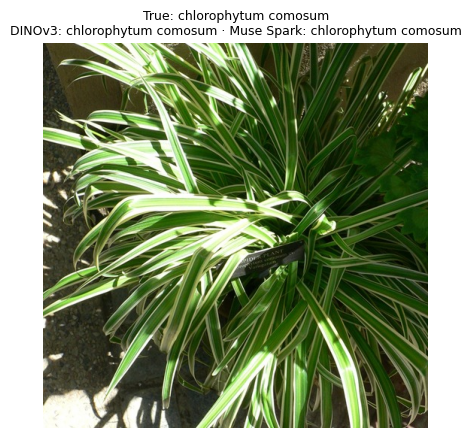

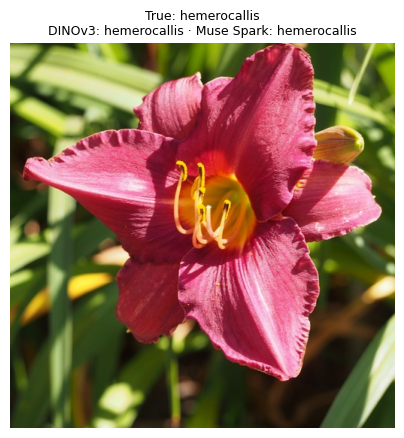

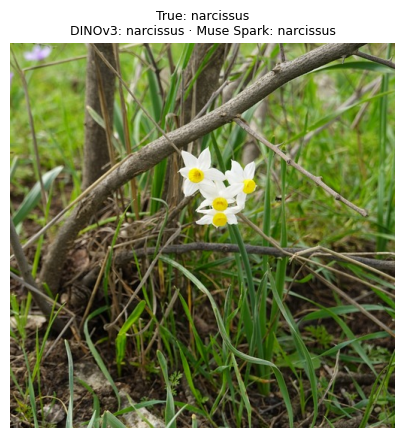

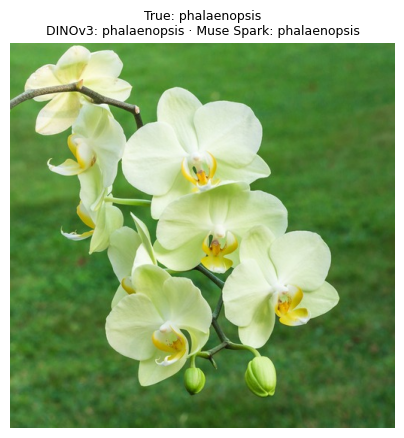

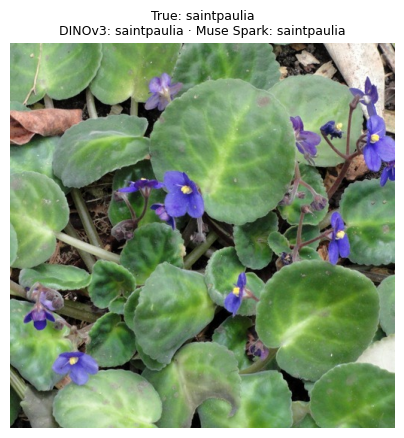

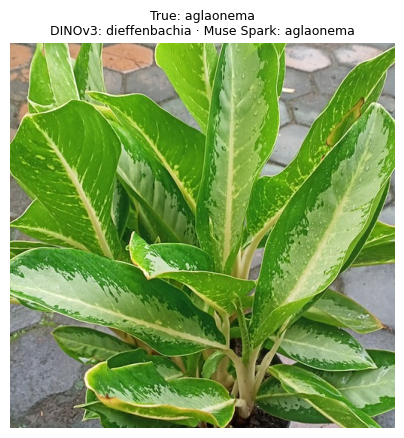

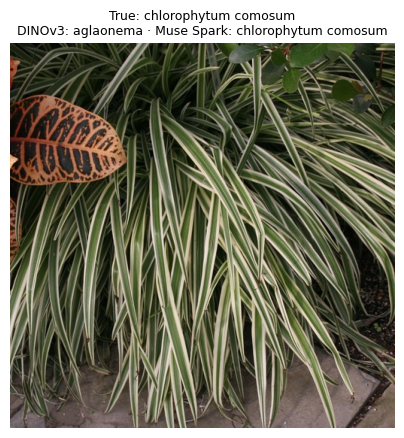

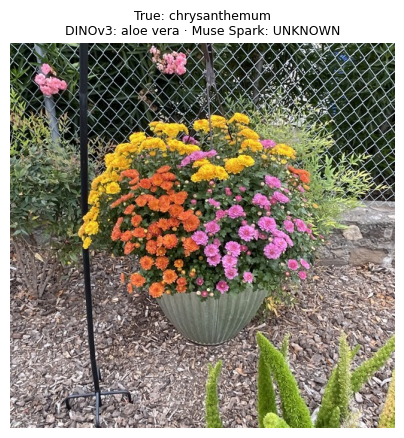

Response cache: /content/drive/MyDrive/AI/meta-global-hackaton/runs/plant_export_v20261026_2355546_holdout10_seed42/muse_spark_dinov3_error_review_muse-spark-1.3_86049a1753aa_a36fa81fded18e69.csv
Comparison CSV: /content/drive/MyDrive/AI/meta-global-hackaton/runs/plant_export_v20261026_2355546_holdout10_seed42/dinov3_error_review_muse-spark-1.3_86049a1753aa_a36fa81fded18e69.csv


In [7]:
meta = cache[['image_id','raw_answer','meta_index','status','input_tokens','cached_input_tokens','output_tokens','estimated_cost_usd']]
results = review.merge(meta,on='image_id',validate='one_to_one')
if results.meta_index.isna().any(): raise ValueError('Some selected images have no cached Meta result.')
results['meta_prediction'] = results.meta_index.astype(int).map(lambda i: CLASS_NAMES[i] if i >= 0 else 'UNKNOWN')
results['meta_correct'] = results.meta_index.astype(int) == results.true_index
results['siglip_correct'] = results.predicted_index == results.true_index
results.to_csv(RESULT_PATH,index=False)
display(results[['review_group','image_id','true_class','predicted_class','meta_prediction','status','siglip_correct','meta_correct']])
display(results.groupby('review_group').agg(images=('image_id','count'),siglip_correct=('siglip_correct','sum'),meta_correct=('meta_correct','sum'),estimated_cost_usd=('estimated_cost_usd','sum')))
for row in results.itertuples(index=False):
    plt.figure(figsize=(5,5))
    plt.imshow(Image.open(BytesIO(selected_images[row.image_id])).convert('RGB'))
    plt.title(f'True: {row.true_class}\nDINOv3: {row.predicted_class} · Muse Spark: {row.meta_prediction}',fontsize=9)
    plt.axis('off'); plt.show()
print('Response cache:', CACHE_PATH)
print('Comparison CSV:', RESULT_PATH)

In [8]:
import pandas as pd
from IPython.display import display, HTML

# Create a clear summary comparison table
summary_data = []
for row in results.itertuples(index=False):
    summary_data.append({
        'Image ID': row.image_id.split('/')[-1],
        'True Class': row.true_class,
        'DINOv3 Prediction': row.predicted_class,
        'DINOv3 Correct': '✓' if row.siglip_correct else '✗',
        'Muse Spark Prediction': row.meta_prediction,
        'Muse Spark Correct': '✓' if row.meta_correct else '✗',
        'Group': row.review_group
    })

summary_df = pd.DataFrame(summary_data)
display(HTML('<h3>DINOv3 vs Muse Spark Classifications</h3>'))
display(summary_df)

,Image ID,True Class,DINOv3 Prediction,DINOv3 Correct,Muse Spark Prediction,Muse Spark Correct,Group
0,001450.jpg,chlorophytum comosum,chlorophytum comosum,✓,chlorophytum comosum,✓,DINOv3 correct sample
1,001777.jpg,hemerocallis,hemerocallis,✓,hemerocallis,✓,DINOv3 correct sample
2,000446.jpg,narcissus,narcissus,✓,narcissus,✓,DINOv3 correct sample
3,001353.jpg,phalaenopsis,phalaenopsis,✓,phalaenopsis,✓,DINOv3 correct sample
4,000217.jpg,saintpaulia,saintpaulia,✓,saintpaulia,✓,DINOv3 correct sample
5,000482.jpg,aglaonema,dieffenbachia,✗,aglaonema,✓,DINOv3 mistake
6,000471.jpg,chlorophytum comosum,aglaonema,✗,chlorophytum comosum,✓,DINOv3 mistake
7,001636.jpg,chrysanthemum,aloe vera,✗,UNKNOWN,✗,DINOv3 mistake


In [9]:
from google.colab import files

# Find the zip member path for 001636.jpg
target_image_id = None
for img_id in selected_images:
    if '001636.jpg' in img_id:
        target_image_id = img_id
        break

if target_image_id:
    # Save bytes locally
    output_path = '001636.jpg'
    with open(output_path, 'wb') as f:
        f.write(selected_images[target_image_id])
    print(f'Successfully saved {target_image_id} to {output_path}. Triggering download...')
    files.download(output_path)
else:
    print('Target image 001636.jpg not found in selected images.')

Successfully saved v20260925_155046/snapshot/val/0005_chrysanthemum/001636.jpg to 001636.jpg. Triggering download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

```markdown
## Conclusions and Review Insights

- **DINOv3 Mistakes Reviewed**: A total of **3** incorrect predictions made by DINOv3 were extracted from the 111-image internal test split.
- **Diagnostic Comparison**:
  - For the **5 correctly classified** sample images, both models successfully agreed and correctly predicted the true classes.
  - Out of the **3 DINOv3 mistakes**, Muse Spark correctly classified **2** of them (e.g., correctly identifying `aglaonema` and `chlorophytum comosum` where DINOv3 failed).
  - One image resulted in an `invalid` classification from Muse Spark due to an empty response, showing that while APIs can provide a strong second opinion, they are still prone to missing values or strict formatting constraints.
- **Takeaway**: Combining multi-modal LLM predictions (like Muse Spark) can act as an effective ensemble technique or validation routine to correct fine-grained classification errors made by vision models like DINOv3.
```

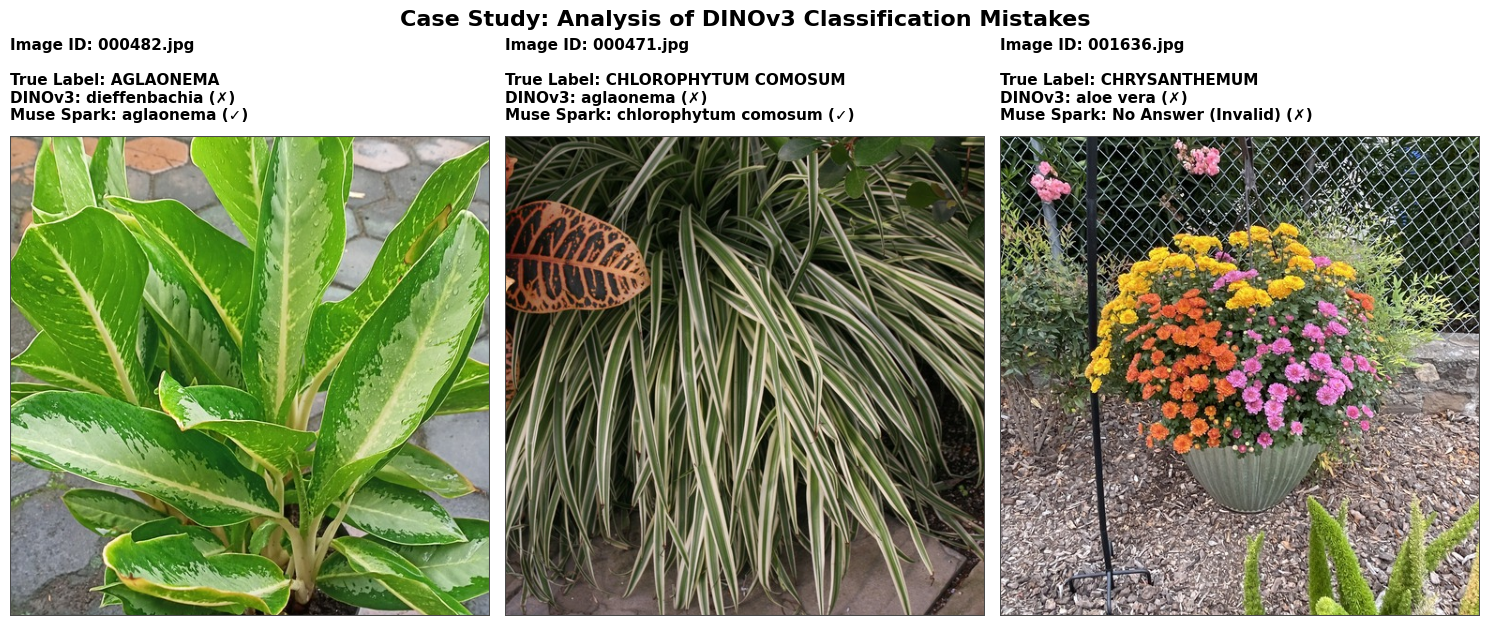

In [10]:
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO

# Filter to only the 3 DINOv3 mistakes
mistakes_df = results[results['review_group'] == 'DINOv3 mistake'].copy()

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
fig.suptitle('Case Study: Analysis of DINOv3 Classification Mistakes', fontsize=16, fontweight='bold', y=1.05)

for i, (ax, row) in enumerate(zip(axes, mistakes_df.itertuples(index=False))):
    # Load and display image
    img_bytes = selected_images[row.image_id]
    with Image.open(BytesIO(img_bytes)) as img:
        ax.imshow(img.convert('RGB'))

    # Determine prediction text and color styling
    dino_color = '#2ca02c' if row.siglip_correct else '#d62728'
    muse_color = '#2ca02c' if row.meta_correct else ('#ff7f0e' if row.status == 'invalid' else '#d62728')

    muse_pred_display = 'No Answer (Invalid)' if row.status == 'invalid' else row.meta_prediction

    title_text = (
        f"Image ID: {row.image_id.split('/')[-1]}\n\n"
        f"True Label: {row.true_class.upper()}\n"
        f"DINOv3: {row.predicted_class} (✗)\n"
        f"Muse Spark: {muse_pred_display} ({'✓' if row.meta_correct else '✗'})"
    )

    # Display clear annotations directly below or as title
    ax.set_title(title_text, fontsize=11, fontweight='semibold', loc='left', pad=12)
    ax.axis('off')

    # Add a styled border color around axes matching the correctness
    rect = plt.Rectangle((0,0), 1, 1, fill=False, color='#4a4a4a', lw=1.5, transform=ax.transAxes)
    ax.add_patch(rect)

plt.tight_layout()
plt.show()